In [1]:
%pip install -q --disable-pip-version-check pandas numpy matplotlib seaborn scikit-learn xgboost ipykernel


Note: you may need to restart the kernel to use updated packages.


### Environment Setup


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

plt.style.use('fivethirtyeight')
plt.rcParams['font.size'] = 11

# Operational Parameters
FORECAST_HORIZON_STEPS = 4        # 4 x 15-min intervals = 1 Hour Ahead
DEMAND_CAP = 100.0                # 100 kWh/15-min interval (~400 kW active power)
QUANTILE_ALPHA = 0.90             # 90th percentile safety envelope
CONTRACT_DEMAND_KVA = 475.0       # 475 kVA Sanctioned Contract Demand
ROLLING_TRAIN_DAYS = 45           # 45-day rolling memory window


### Data Loading and Preprocessing


In [3]:
df_raw = pd.read_csv('Steel_industry_data.csv')
df_raw['date'] = pd.to_datetime(df_raw['date'], format='%d/%m/%Y %H:%M')
df = df_raw.sort_values('date').set_index('date')

pf = df['Lagging_Current_Power_Factor'].clip(lower=50.0) / 100.0
df['Demand_kVA'] = (df['Usage_kWh'] * 4) / pf

peak_demand = df['Demand_kVA'].max()
excess_demand = max(0, peak_demand - CONTRACT_DEMAND_KVA)
breach_count = (df['Demand_kVA'] > CONTRACT_DEMAND_KVA).sum()

print(f"Total Intervals: {len(df):,}")
print(f"Peak Demand: {peak_demand:.1f} kVA")
print(f"Excess over Contract Demand: {excess_demand:.1f} kVA")
print(f"Intervals Above Contract Demand: {breach_count}")


Total Intervals: 35,040
Peak Demand: 701.4 kVA
Excess over Contract Demand: 226.4 kVA
Intervals Above Contract Demand: 1055


### Visualization and Analysis


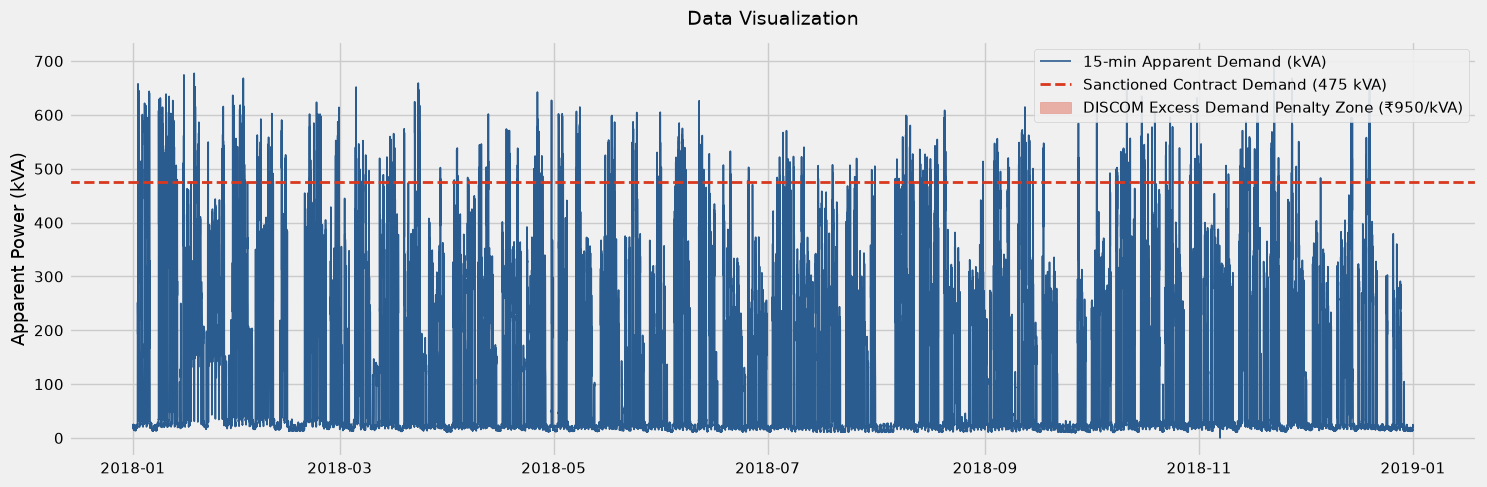

In [4]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.index, df['Demand_kVA'], color='#2b5c8f', lw=1.2, label='15-min Apparent Demand (kVA)')
ax.axhline(CONTRACT_DEMAND_KVA, color='#d9381e', linestyle='--', lw=2, label=f'Sanctioned Contract Demand ({CONTRACT_DEMAND_KVA:.0f} kVA)')
ax.fill_between(df.index, CONTRACT_DEMAND_KVA, df['Demand_kVA'], where=(df['Demand_kVA'] > CONTRACT_DEMAND_KVA),
                 color='#d9381e', alpha=0.35, label='DISCOM Excess Demand Penalty Zone (₹950/kVA)')
ax.set_title('Data Visualization', fontsize=14, pad=12)
ax.set_ylabel('Apparent Power (kVA)')
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()


### Feature Engineering


In [5]:
def build_cold_start_features(data, horizon=4):
    d = data.copy()
    
    d['target'] = d['Usage_kWh'].shift(-horizon)
    d['target_pf'] = (d['Lagging_Current_Power_Factor'].clip(lower=50.0) / 100.0).shift(-horizon)
    
    # 1. HISTORICAL USAGE LAGS
    d['usage_now']      = d['Usage_kWh']             # Usage right now at time t
    d['usage_lag_15m']  = d['Usage_kWh'].shift(1)    # 15 mins ago
    d['usage_lag_30m']  = d['Usage_kWh'].shift(2)    # 30 mins ago
    d['usage_lag_1h']   = d['Usage_kWh'].shift(4)    # 1 hour ago
    d['usage_lag_2h']   = d['Usage_kWh'].shift(8)    # 2 hours ago
    d['usage_lag_24h']  = d['Usage_kWh'].shift(96)   # 24 hours ago (yesterday same time)
    
    # 2. ELECTRICAL TELEMETRY
    d['reactive_power_now']    = d['Lagging_Current_Reactive.Power_kVarh']
    d['reactive_power_lag_1h'] = d['Lagging_Current_Reactive.Power_kVarh'].shift(4)
    d['power_factor_now']      = d['Lagging_Current_Power_Factor']
    
    # 3. ROLLING INDUSTRIAL STATISTICS
    d['rolling_max_1h']  = d['Usage_kWh'].rolling(4).max()
    d['rolling_mean_1h'] = d['Usage_kWh'].rolling(4).mean()
    d['rolling_max_4h']  = d['Usage_kWh'].rolling(16).max()
    d['rolling_mean_4h'] = d['Usage_kWh'].rolling(16).mean()
    d['rolling_max_24h'] = d['Usage_kWh'].rolling(96).max()
    
    d['ramp_rate_15m'] = d['Usage_kWh'] - d['Usage_kWh'].shift(1)
    d['ramp_rate_1h']  = d['Usage_kWh'] - d['Usage_kWh'].shift(4)
    
    # 4. CALENDAR & CYCLIC ENCODING
    d['hour']       = d.index.hour
    d['dayofweek']  = d.index.dayofweek
    d['month']      = d.index.month
    d['is_weekend'] = (d.index.dayofweek >= 5).astype(int)
    
    d['hour_sin'] = np.sin(2 * np.pi * d.index.hour / 24)
    d['hour_cos'] = np.cos(2 * np.pi * d.index.hour / 24)
    
    # Map load types to numerical codes
    load_type_map = {'Light_Load': 0, 'Medium_Load': 1, 'Maximum_Load': 2}
    d['load_type_code'] = d['Load_Type'].map(load_type_map)
    
    return d.dropna().copy()

df_feat = build_cold_start_features(df, horizon=FORECAST_HORIZON_STEPS)
print(f"Usable samples after feature engineering: {len(df_feat):,} intervals ({len(df_feat)/96:.1f} days)")


Usable samples after feature engineering: 34,940 intervals (364.0 days)


### Training the Model (Daily Walk-Forward)

**What changed from MK2:**
Instead of evaluating on a static split with a single quantile model that overshoots,
MK3 trains a dual-model system (Baseline Tracker + Spike Guard) starting with the full
30 days of January. We walk forward day-by-day through the year (Feb to Dec), predict
1 hour ahead, evaluate errors at midnight, update sample weights, and retrain for the next day.


In [6]:
FEATURE_COLS = [
    'usage_now', 'usage_lag_15m', 'usage_lag_30m', 'usage_lag_1h', 'usage_lag_2h', 'usage_lag_24h',
    'reactive_power_now', 'reactive_power_lag_1h', 'power_factor_now',
    'rolling_max_1h', 'rolling_mean_1h', 'rolling_max_4h', 'rolling_mean_4h', 'rolling_max_24h',
    'ramp_rate_15m', 'ramp_rate_1h',
    'hour', 'dayofweek', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'load_type_code'
]

dates = pd.date_range('2018-02-01', '2018-12-31')

# Cold Start: Full January
history_df = df_feat.loc[df_feat.index < '2018-02-01'].copy()
history_weights = np.where(history_df['target'] >= DEMAND_CAP, 3.0, 1.0)

m_tracker = xgb.XGBRegressor(n_estimators=75, max_depth=4, learning_rate=0.08, n_jobs=-1, random_state=42)
m_guard   = xgb.XGBRegressor(objective='reg:quantileerror', quantile_alpha=QUANTILE_ALPHA, n_estimators=75, max_depth=4, learning_rate=0.08, n_jobs=-1, random_state=42)

m_tracker.fit(history_df[FEATURE_COLS], history_df['target'], sample_weight=history_weights)
m_guard.fit(history_df[FEATURE_COLS], history_df['target'], sample_weight=history_weights)

preds_tracker_all, preds_guard_all, all_test_idx = [], [], []

for dt in dates:
    day_mask = (df_feat.index >= dt) & (df_feat.index < dt + pd.Timedelta(days=1))
    if not day_mask.any():
        continue
    day_df = df_feat.loc[day_mask]
    
    # 1. Day T predictions (1-hour ahead)
    p_tr = m_tracker.predict(day_df[FEATURE_COLS])
    p_gd = m_guard.predict(day_df[FEATURE_COLS])
    
    preds_tracker_all.extend(p_tr)
    preds_guard_all.extend(p_gd)
    all_test_idx.extend(day_df.index)
    
    # 2. Midnight error reflection & sample weighting
    actual_day = day_df['target'].values
    residuals  = np.abs(p_tr - actual_day)
    missed     = (actual_day >= DEMAND_CAP) & (p_gd < DEMAND_CAP)
    day_weights = 1.0 + np.where(residuals > 20.0, 2.0, 0.0) + np.where(missed, 4.0, 0.0)
    
    # 3. Append Day T and retrain for tomorrow
    history_df = pd.concat([history_df, day_df])
    history_weights = np.concatenate([history_weights, day_weights])
    
    cutoff = dt - pd.Timedelta(days=ROLLING_TRAIN_DAYS)
    keep_mask = history_df.index >= cutoff
    history_df = history_df.loc[keep_mask]
    history_weights = history_weights[keep_mask]
    
    m_tracker.fit(history_df[FEATURE_COLS], history_df['target'], sample_weight=history_weights)
    m_guard.fit(history_df[FEATURE_COLS], history_df['target'], sample_weight=history_weights)

eval_df = df_feat.loc[all_test_idx].copy()
eval_df['pred_tracker_kwh'] = preds_tracker_all
eval_df['pred_guard_kwh']   = preds_guard_all
eval_df['current_pf']       = eval_df['power_factor_now'].clip(lower=50.0) / 100.0
eval_df['actual_kva']       = (eval_df['target'] * 4.0) / eval_df['target_pf']
eval_df['pred_tracker_kva'] = (eval_df['pred_tracker_kwh'] * 4.0) / eval_df['current_pf']
eval_df['pred_guard_kva']   = (eval_df['pred_guard_kwh'] * 4.0) / eval_df['current_pf']

print(f"Daily walk-forward complete: {len(eval_df):,} intervals across {len(dates)} days.")


Daily walk-forward complete: 32,060 intervals across 334 days.


### Spike Detection Scorecard


In [7]:
monthly_metrics = []

for m, grp in eval_df.groupby(eval_df.index.to_period('M')):
    spikes     = grp.loc[grp['target'] >= DEMAND_CAP]
    non_spikes = grp.loc[grp['target'] < DEMAND_CAP]
    tot_spikes = len(spikes)
    
    if tot_spikes == 0:
        continue
        
    caught       = int((spikes['pred_guard_kwh'] >= DEMAND_CAP).sum())
    missed       = tot_spikes - caught
    false_alarms = int((non_spikes['pred_guard_kwh'] >= DEMAND_CAP).sum())
    
    recall    = (caught / tot_spikes) * 100
    precision = (caught / (caught + false_alarms)) * 100 if (caught + false_alarms) > 0 else 0
    act_mean  = float(spikes['target'].mean())
    tr_mean   = float(spikes['pred_tracker_kwh'].mean())
    captured  = (tr_mean / act_mean) * 100
    miss_gap  = float(DEMAND_CAP - spikes.loc[spikes['pred_guard_kwh'] < DEMAND_CAP, 'pred_guard_kwh'].mean()) if missed > 0 else 0.0
    
    monthly_metrics.append({
        'Month': str(m),
        'Total Spikes': tot_spikes,
        'Caught': caught,
        'Missed': missed,
        'Recall (%)': round(recall, 1),
        'Precision (%)': round(precision, 1),
        'Actual Mean (kWh)': round(act_mean, 1),
        'Pred Mean (kWh)': round(tr_mean, 1),
        '% Height Captured': f"{captured:.1f}%",
        'Avg Miss Gap (kWh)': round(miss_gap, 1)
    })

spike_summary_df = pd.DataFrame(monthly_metrics)
print(spike_summary_df.to_string(index=False))
print("-" * 95)
tot_s = spike_summary_df['Total Spikes'].sum()
tot_c = spike_summary_df['Caught'].sum()
tot_m = spike_summary_df['Missed'].sum()
print(f"Overall Annual Recall: {tot_c / tot_s * 100:.1f}% ({tot_c} caught out of {tot_s} spikes | {tot_m} missed)")


  Month  Total Spikes  Caught  Missed  Recall (%)  Precision (%)  Actual Mean (kWh)  Pred Mean (kWh) % Height Captured  Avg Miss Gap (kWh)
2018-02           199     187      12        94.0           20.6              114.5             86.3             75.4%                 9.1
2018-03           112      92      20        82.1           10.6              114.6             71.5             62.4%                 8.8
2018-04           105      87      18        82.9           11.2              110.5             68.5             62.0%                13.1
2018-05           171     158      13        92.4           18.1              112.4             78.7             70.1%                 6.9
2018-06            78      64      14        82.1           10.8              111.0             70.5             63.5%                11.5
2018-07            86      42      44        48.8            7.6              108.1             68.8             63.6%                12.3
2018-08           112      

### Monthly Demand Forecast & Spike Visualizations


[February 2018] Spikes: 199 | Caught: 187 (94.0%) | Missed: 12 | Pred on Spikes: 86.3 kWh (75.4% captured) | Miss Gap: -9.1 kWh


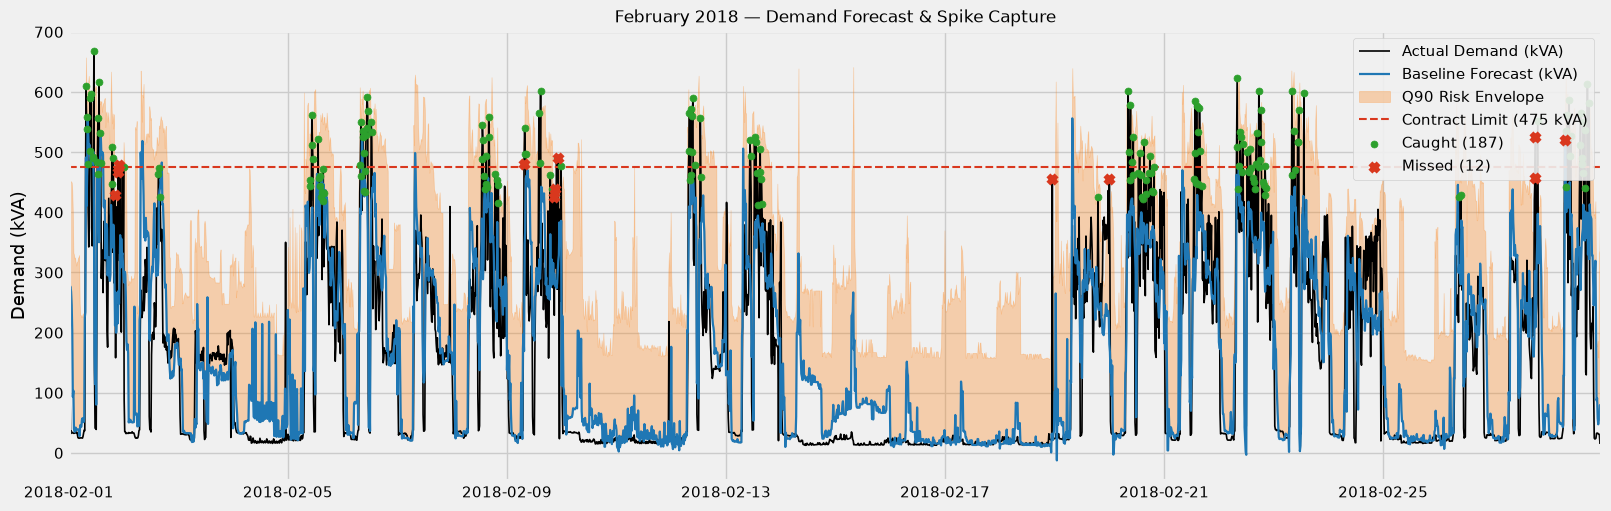

[March 2018] Spikes: 112 | Caught: 92 (82.1%) | Missed: 20 | Pred on Spikes: 71.5 kWh (62.4% captured) | Miss Gap: -8.8 kWh


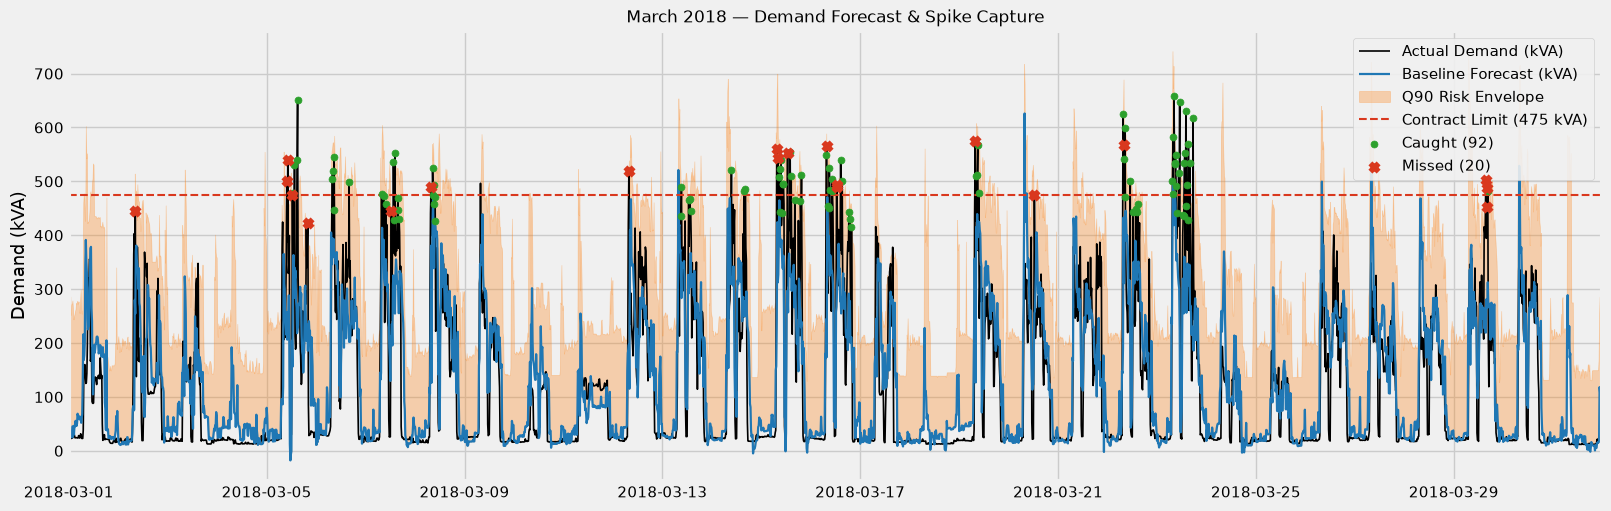

[April 2018] Spikes: 105 | Caught: 87 (82.9%) | Missed: 18 | Pred on Spikes: 68.5 kWh (62.0% captured) | Miss Gap: -13.1 kWh


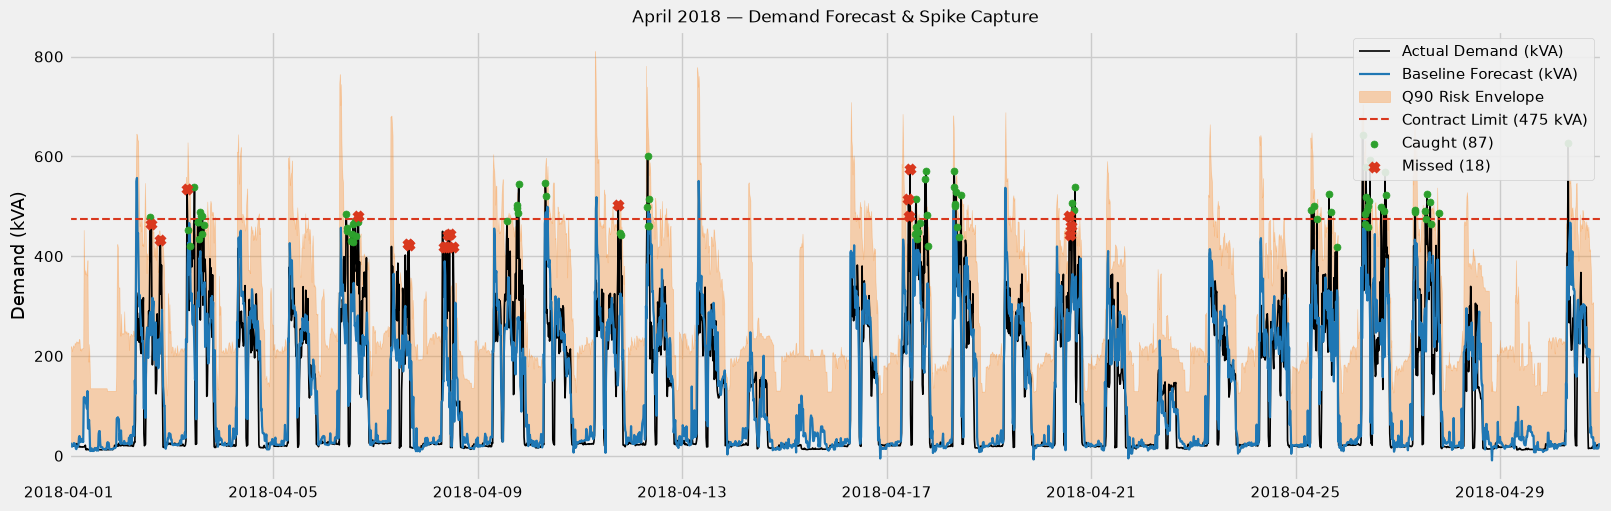

[May 2018] Spikes: 171 | Caught: 158 (92.4%) | Missed: 13 | Pred on Spikes: 78.7 kWh (70.1% captured) | Miss Gap: -6.9 kWh


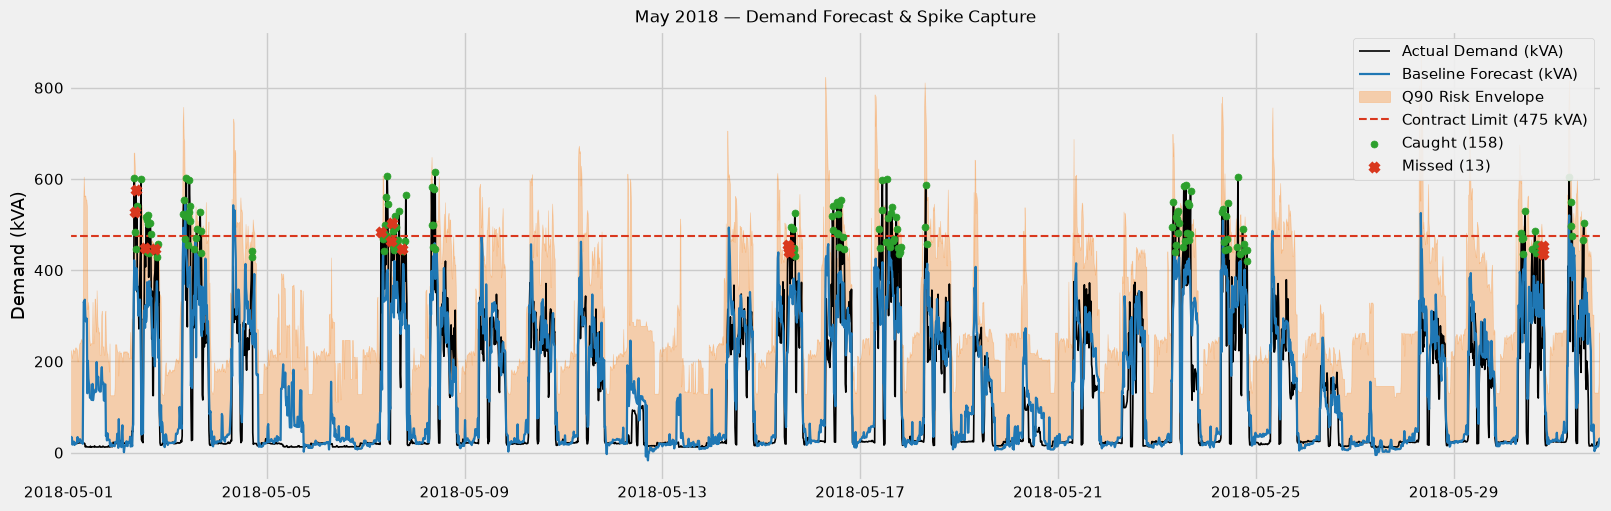

[June 2018] Spikes: 78 | Caught: 64 (82.1%) | Missed: 14 | Pred on Spikes: 70.5 kWh (63.5% captured) | Miss Gap: -11.5 kWh


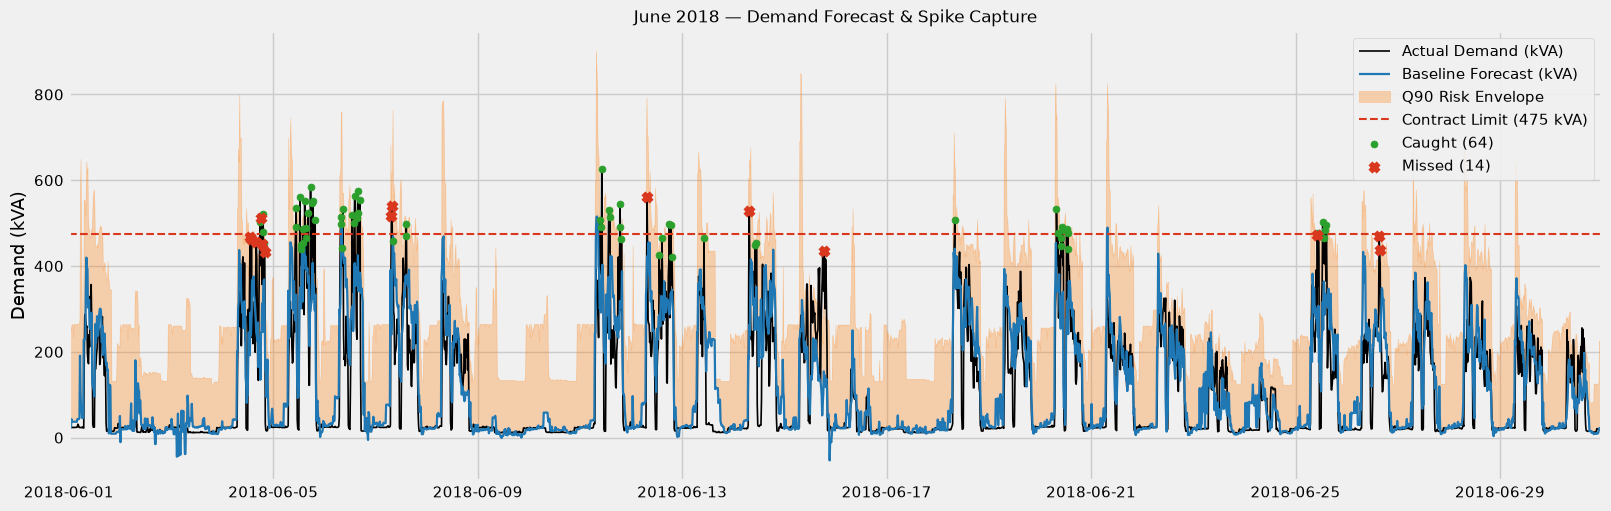

[July 2018] Spikes: 86 | Caught: 42 (48.8%) | Missed: 44 | Pred on Spikes: 68.8 kWh (63.6% captured) | Miss Gap: -12.3 kWh


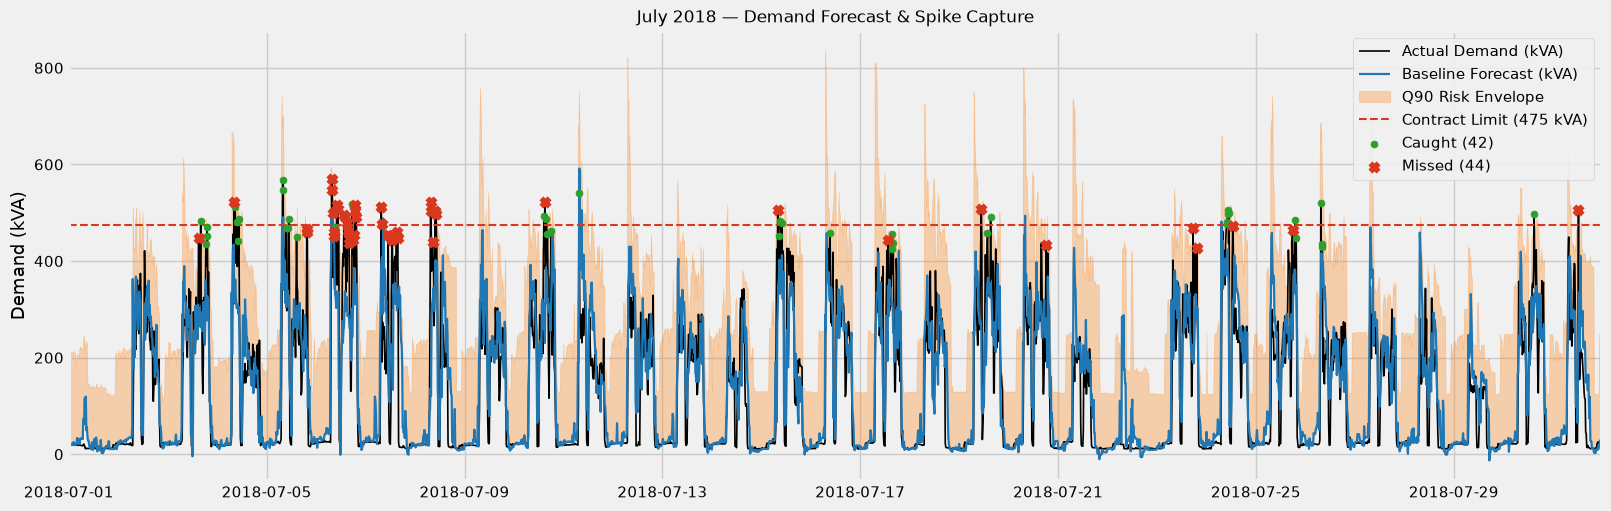

[August 2018] Spikes: 112 | Caught: 99 (88.4%) | Missed: 13 | Pred on Spikes: 73.9 kWh (67.6% captured) | Miss Gap: -9.4 kWh


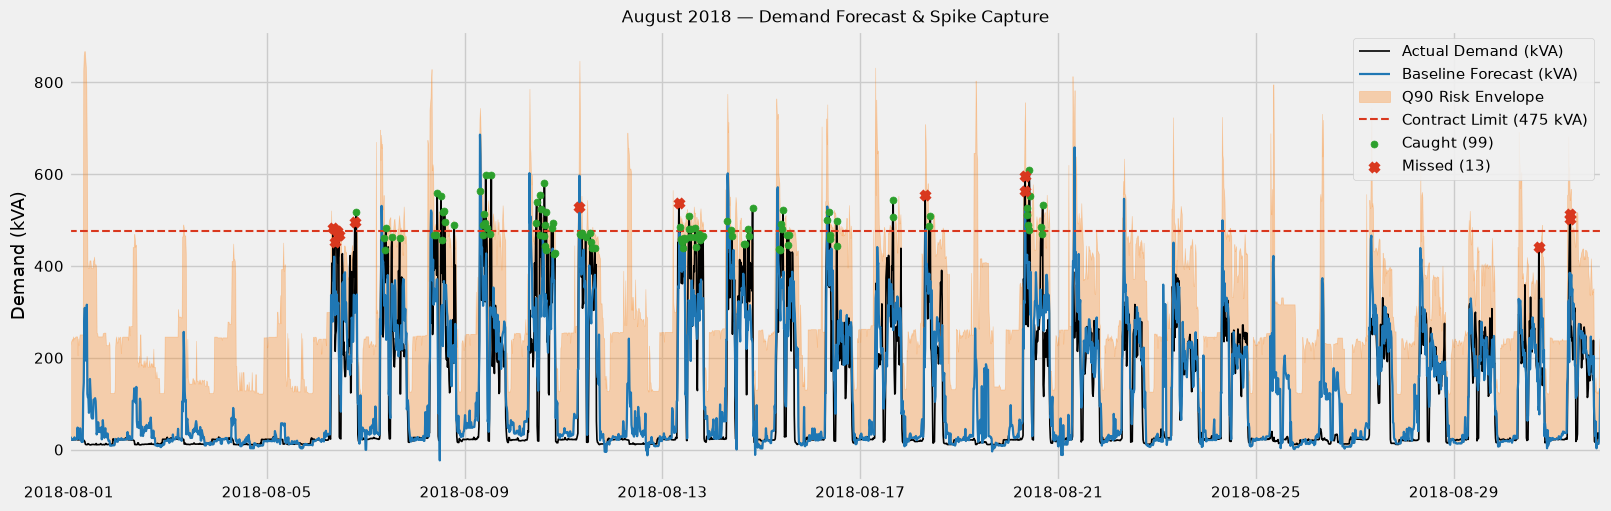

[September 2018] Spikes: 91 | Caught: 78 (85.7%) | Missed: 13 | Pred on Spikes: 73.3 kWh (66.0% captured) | Miss Gap: -17.7 kWh


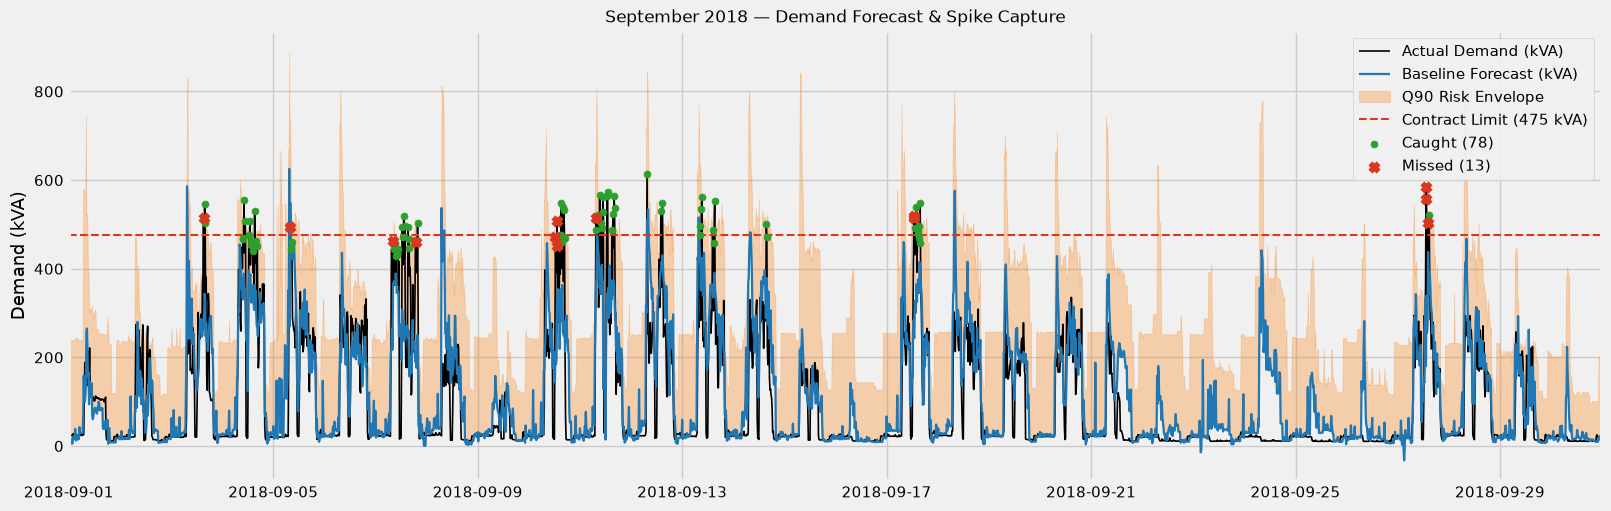

[October 2018] Spikes: 140 | Caught: 110 (78.6%) | Missed: 30 | Pred on Spikes: 74.1 kWh (65.9% captured) | Miss Gap: -13.0 kWh


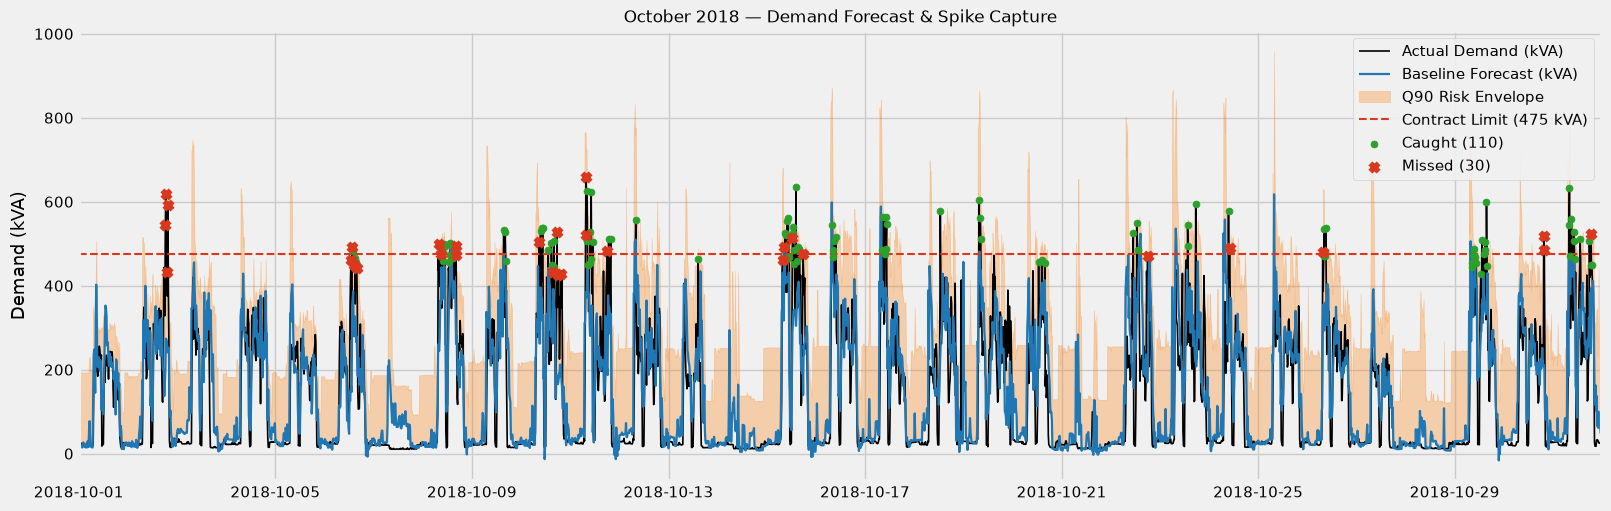

[November 2018] Spikes: 139 | Caught: 126 (90.6%) | Missed: 13 | Pred on Spikes: 73.9 kWh (64.6% captured) | Miss Gap: -6.8 kWh


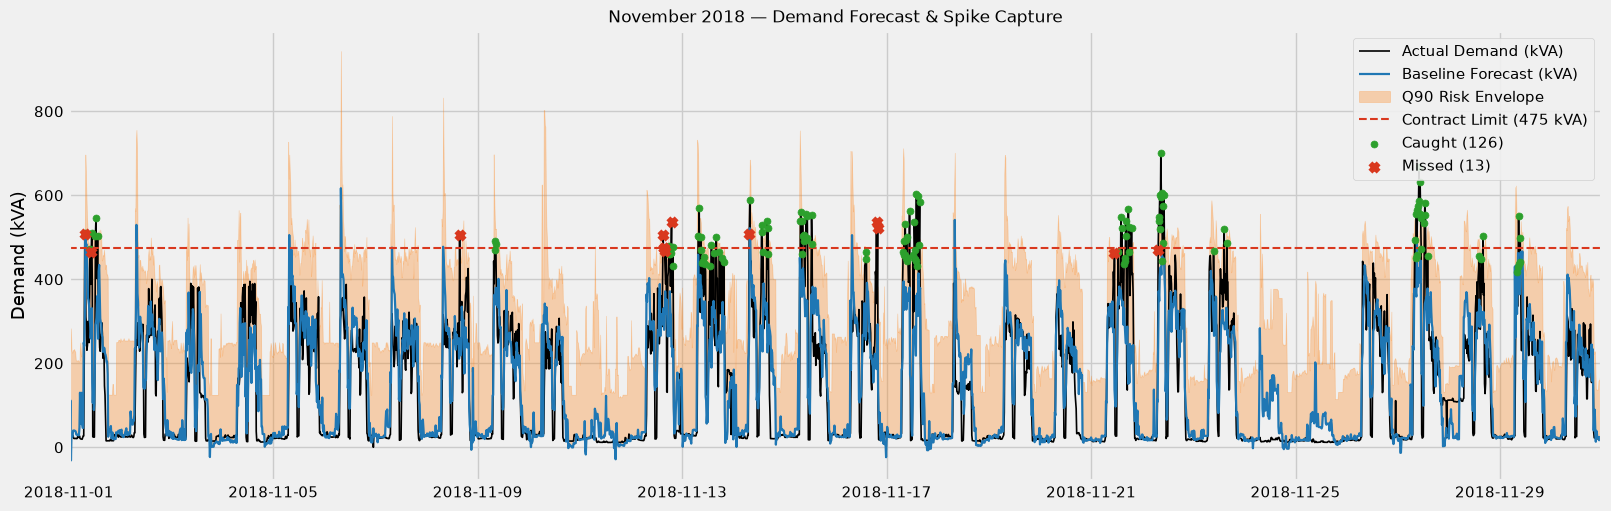

[December 2018] Spikes: 46 | Caught: 37 (80.4%) | Missed: 9 | Pred on Spikes: 75.4 kWh (64.2% captured) | Miss Gap: -13.1 kWh


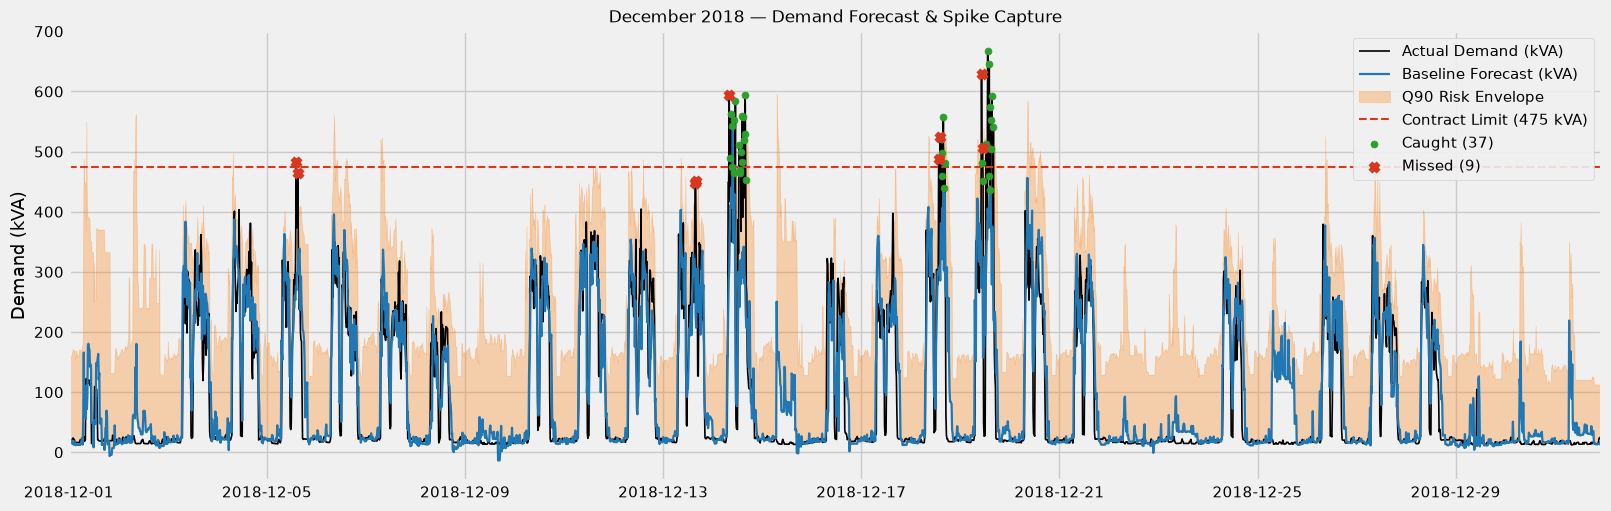

In [8]:
for m, grp in eval_df.groupby(eval_df.index.to_period('M')):
    spikes     = grp.loc[grp['target'] >= DEMAND_CAP]
    tot_spikes = len(spikes)
    caught     = int((spikes['pred_guard_kwh'] >= DEMAND_CAP).sum())
    missed     = tot_spikes - caught
    recall     = (caught / tot_spikes) * 100 if tot_spikes > 0 else 0
    act_mean   = float(spikes['target'].mean()) if tot_spikes > 0 else 0
    tr_mean    = float(spikes['pred_tracker_kwh'].mean()) if tot_spikes > 0 else 0
    captured   = (tr_mean / act_mean) * 100 if act_mean > 0 else 0
    miss_gap   = float(DEMAND_CAP - spikes.loc[spikes['pred_guard_kwh'] < DEMAND_CAP, 'pred_guard_kwh'].mean()) if missed > 0 else 0.0
    
    print(f"[{m.strftime('%B %Y')}] Spikes: {tot_spikes} | Caught: {caught} ({recall:.1f}%) | Missed: {missed} | Pred on Spikes: {tr_mean:.1f} kWh ({captured:.1f}% captured)" + (f" | Miss Gap: -{miss_gap:.1f} kWh" if missed > 0 else ""))
    
    fig, ax = plt.subplots(figsize=(16, 5), constrained_layout=True)
    ax.plot(grp.index, grp['actual_kva'], color='black', lw=1.2, label='Actual Demand (kVA)')
    ax.plot(grp.index, grp['pred_tracker_kva'], color='#1f77b4', lw=1.6, label='Baseline Forecast (kVA)')
    ax.fill_between(grp.index, grp['pred_tracker_kva'], grp['pred_guard_kva'], color='#ff7f0e', alpha=0.30, label='Q90 Risk Envelope')
    ax.axhline(CONTRACT_DEMAND_KVA, color='#d9381e', ls='--', lw=1.5, label=f'Contract Limit ({CONTRACT_DEMAND_KVA:.0f} kVA)')
    
    caught_idx = spikes.loc[spikes['pred_guard_kwh'] >= DEMAND_CAP].index
    missed_idx = spikes.loc[spikes['pred_guard_kwh'] < DEMAND_CAP].index
    
    if len(caught_idx) > 0:
        ax.scatter(caught_idx, grp.loc[caught_idx, 'actual_kva'], color='#2ca02c', s=25, zorder=5, label=f'Caught ({caught})')
    if len(missed_idx) > 0:
        ax.scatter(missed_idx, grp.loc[missed_idx, 'actual_kva'], color='#d9381e', s=35, marker='x', zorder=6, label=f'Missed ({missed})')
        
    ax.set_ylabel('Demand (kVA)')
    ax.set_title(f'{m.strftime("%B %Y")} — Demand Forecast & Spike Capture', fontsize=12)
    ax.legend(loc='upper right', framealpha=0.9)
    ax.margins(x=0)
    plt.show()


### Feature Importance


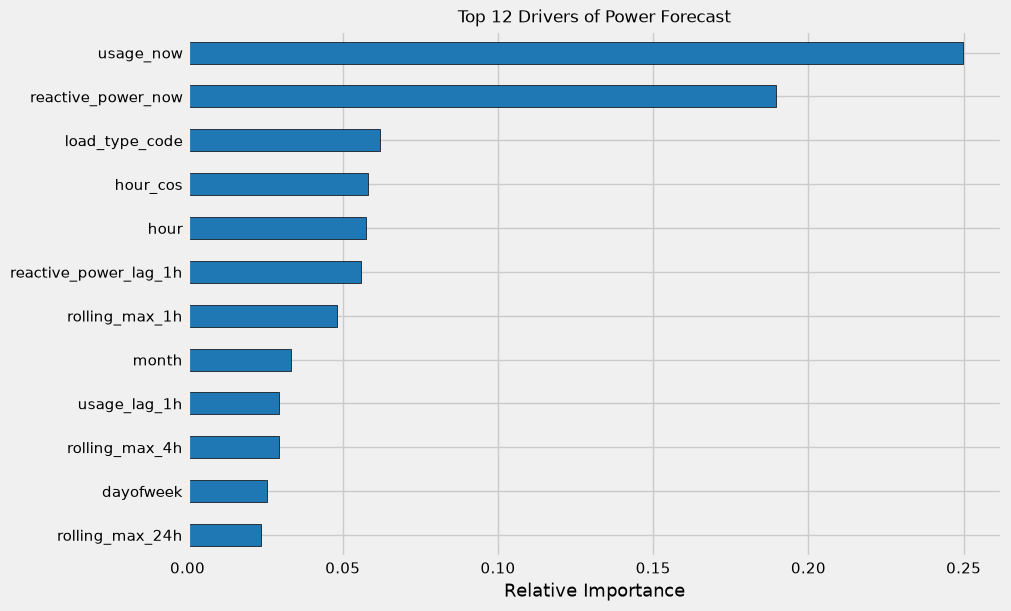

In [9]:
importances = pd.Series(m_tracker.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
importances.tail(12).plot(kind='barh', ax=ax, color='#1f77b4', edgecolor='black')
ax.set_title('Top 12 Drivers of Power Forecast', fontsize=12)
ax.set_xlabel('Relative Importance')
plt.show()
